In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

url = "https://raw.githubusercontent.com/manoelgadi/PSDMA/refs/heads/main/datasets/UN.csv"

df = pd.read_csv("./UN.csv")

display(df.head())
print("Dataset shape:", df.shape)


FileNotFoundError: [Errno 2] No such file or directory: './UN.csv'

In [ ]:
df.info()

print("Missing values:")
display(df.isnull().sum())

print("Summary statistics:")
display(df.describe(include="all"))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   country                 207 non-null    object 
 1   region                  207 non-null    object 
 2   tfr                     197 non-null    float64
 3   contraception           144 non-null    float64
 4   educationMale           76 non-null     float64
 5   educationFemale         76 non-null     float64
 6   lifeMale                196 non-null    float64
 7   lifeFemale              196 non-null    float64
 8   infantMortality         201 non-null    float64
 9   GDPperCapita            197 non-null    float64
 10  economicActivityMale    165 non-null    float64
 11  economicActivityFemale  165 non-null    float64
 12  illiteracyMale          160 non-null    float64
 13  illiteracyFemale        160 non-null    float64
dtypes: float64(12), object(2)
memory usage: 22

country                     0
region                      0
tfr                        10
contraception              63
educationMale             131
educationFemale           131
lifeMale                   11
lifeFemale                 11
infantMortality             6
GDPperCapita               10
economicActivityMale       42
economicActivityFemale     42
illiteracyMale             47
illiteracyFemale           47
dtype: int64

Summary statistics:


,country,region,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
count,207,207,197.000000,144.000000,76.000000,76.000000,196.00000,196.000000,201.000000,197.000000,165.000000,165.000000,160.000000,160.000000
unique,207,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Afghanistan,Africa,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,3.528782,43.430556,11.410526,11.275000,63.62551,68.391837,43.477612,6261.954315,76.460606,46.794545,17.554662,27.906200
std,NaN,NaN,1.761974,23.706732,3.049834,3.475135,9.78687,11.041234,38.756041,9355.659390,7.687047,16.810472,17.813000,26.580664
min,NaN,NaN,1.190000,2.000000,3.300000,2.000000,36.00000,39.100000,2.000000,36.000000,51.200000,1.900000,0.200000,0.200000
25%,NaN,NaN,1.950000,21.000000,9.750000,9.325000,57.37500,59.600000,12.000000,442.000000,72.300000,37.000000,2.952000,4.847000
50%,NaN,NaN,3.070000,47.000000,11.250000,11.650000,66.50000,72.150000,30.000000,1779.000000,76.800000,48.400000,10.829000,20.100000
75%,NaN,NaN,4.980000,64.000000,13.900000,13.650000,70.90000,76.425000,66.000000,7272.000000,81.200000,56.400000,27.575000,48.025000


In [ ]:

# Identify the country column
country_col = next(
    (c for c in df.columns
     if c.lower().strip() in ["country", "country name", "name"]),
    df.select_dtypes(include=["object", "string"]).columns[0]
)

countries = df[country_col].astype(str).reset_index(drop=True)

# Select numerical columns
X = df.select_dtypes(include=np.number).copy()

# Exclude numerical identifiers
X = X.drop(
    columns=[
        c for c in X.columns
        if c.lower().strip() in
        ["id", "index", "country_id", "country_code", "year"]
    ],
    errors="ignore"
)

# Remove columns with no usable variation
X = X.loc[:, X.notna().any()]
X = X.loc[:, X.nunique(dropna=True) > 1]

X = X.replace([np.inf, -np.inf], np.nan)

# Replace missing values with the median
imputer = SimpleImputer(strategy="median")

X_clean = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

display(X_clean.head())
print("Remaining missing values:", X_clean.isnull().sum().sum())


,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,6.90,47.0,11.25,11.65,45.0,46.00,154.0,2848.0,87.5,7.2,52.800,85.00
1,2.60,47.0,11.25,11.65,68.0,74.00,32.0,863.0,76.8,48.4,10.829,20.10
2,3.81,52.0,11.10,9.90,67.5,70.30,44.0,1531.0,76.4,7.8,26.100,51.00
3,3.07,47.0,11.25,11.65,68.0,73.00,11.0,1779.0,58.8,42.4,0.264,0.36
4,3.07,47.0,11.25,11.65,66.5,72.15,30.0,1779.0,76.8,48.4,10.829,20.10


Remaining missing values: 0


PCA and K-Means require numerical data, so we exclude the country names from the calculations but keep them for interpretation later.
We replace missing values using the median.
For example, suppose five countries have incomes:
1000, 2000, 3000, 4000, missing
The median is 2500, so the missing income becomes 2500.
The median is often preferable to the mean when variables contain extreme values.



In [ ]:

Q1 = X_clean.quantile(0.25)
Q3 = X_clean.quantile(0.75)

IQR = Q3 - Q1

outliers = (
    (X_clean < Q1 - 1.5 * IQR) |
    (X_clean > Q3 + 1.5 * IQR)
)

print("Number of outliers per variable:")
display(outliers.sum())

print("Countries with at least one flagged value:")
display(countries[outliers.any(axis=1)])


Number of outliers per variable:


tfr                        0
contraception              0
educationMale             76
educationFemale           76
lifeMale                   1
lifeFemale                 0
infantMortality            4
GDPperCapita              31
economicActivityMale      20
economicActivityFemale    26
illiteracyMale            18
illiteracyFemale           5
dtype: int64

Countries with at least one flagged value:


0         Afghanistan
2             Algeria
3      American.Samoa
9           Australia
10            Austria
            ...      
198           Vanuatu
199         Venezuela
200          Viet.Nam
203             Yemen
205            Zambia
Name: country, Length: 120, dtype: object

An outlier is a value unusually far from the others.
For example, a country with extremely high GDP per capita might be flagged as an outlier.
Our decision: Keep the outliers because differences between countries are exactly what we want to investigate. However, we should check whether extreme values represent genuine observations or data errors.

In [ ]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_clean)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X_clean.columns
)

display(X_scaled_df.head())


,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,1.975954,0.125584,-0.032076,0.065576,-1.972337,-2.101632,2.906362,-0.349277,1.603042,-2.665466,2.317990,2.502358
1,-0.527921,0.125584,-0.032076,0.065576,0.443422,0.503134,-0.290522,-0.566115,0.039531,0.085446,-0.327698,-0.256491
2,0.176658,0.378463,-0.113713,-0.767924,0.390905,0.158933,0.023925,-0.493144,-0.018918,-2.625404,0.634926,1.057044
3,-0.254241,0.125584,-0.032076,0.065576,0.443422,0.410107,-0.840806,-0.466053,-2.590676,-0.315172,-0.993675,-1.095624
4,-0.254241,0.125584,-0.032076,0.065576,0.285872,0.331034,-0.342930,-0.466053,0.039531,0.085446,-0.327698,-0.256491


It transforms each variable to have mean 0 and standard deviation 1.
This means the variables become comparable.

In [ ]:

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

pca_table = pd.DataFrame({
    "PC": range(1, len(explained_variance) + 1),
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

display(pca_table.round(2))


,PC,Explained Variance (%),Cumulative Variance (%)
0,1,53.19,53.19
1,2,13.10,66.29
2,3,9.35,75.64
3,4,8.41,84.05
4,5,5.59,89.64
5,6,4.00,93.63
6,7,3.45,97.09
7,8,1.64,98.73
8,9,0.59,99.32
9,10,0.36,99.68


PCA creates new variables called principal components (PCs). Each component combines information from the original numerical variables.
- PC1 captures the greatest possible variance.
- PC2 captures the greatest remaining variance, independently of PC1.
- PC3 captures the greatest remaining variance, independently of PC1 and PC2.
For example, if income and life expectancy are strongly related, PCA might summarize much of their shared variation in PC1.
fit_transform() calculates the principal components and gives every country its coordinates on them.
explained_variance_ratio_ tells us the percentage of total variance captured by each PC.

Components needed for 90% variance: 6


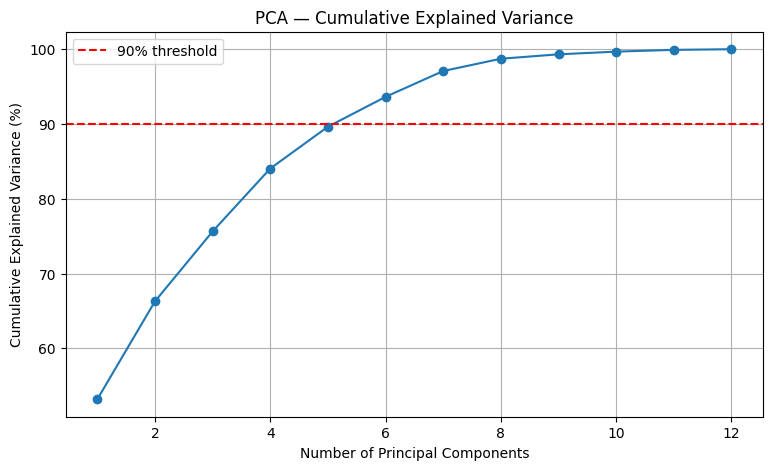

In [ ]:

n_components_90 = np.searchsorted(
    cumulative_variance, 0.90
) + 1

print("Components needed for 90% variance:", n_components_90)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)

plt.axhline(
    y=90,
    color="red",
    linestyle="--",
    label="90% threshold"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA — Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.show()


We would retain 5 principal components, because together they capture 90% of the original variance.

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12
tfr,-0.347,0.084,-0.084,-0.014,-0.146,-0.205,0.320,0.831,0.008,-0.041,0.030,0.085
contraception,0.291,0.073,0.155,0.130,-0.203,0.845,0.262,0.199,-0.039,-0.052,0.014,0.019
educationMale,0.250,0.572,-0.024,-0.188,-0.198,-0.112,-0.044,0.003,0.076,0.482,0.530,-0.040
educationFemale,0.248,0.550,0.005,-0.205,-0.290,-0.158,-0.115,-0.007,-0.078,-0.447,-0.514,0.034
lifeMale,0.357,-0.092,-0.123,0.312,0.027,-0.096,-0.214,0.278,0.473,0.003,-0.109,-0.619
lifeFemale,0.369,-0.111,-0.084,0.233,0.054,-0.093,-0.245,0.154,0.319,-0.076,0.085,0.762
infantMortality,-0.361,0.157,0.066,-0.183,-0.025,0.129,0.242,-0.250,0.800,-0.162,0.015,0.054
GDPperCapita,0.232,0.306,0.104,0.314,0.597,-0.195,0.577,-0.086,-0.057,-0.069,-0.021,0.004
economicActivityMale,-0.165,0.028,0.369,0.657,-0.547,-0.224,0.089,-0.209,-0.027,0.042,0.021,0.019
economicActivityFemale,0.022,-0.019,0.885,-0.215,0.226,-0.051,-0.250,0.223,0.058,0.026,-0.008,-0.019


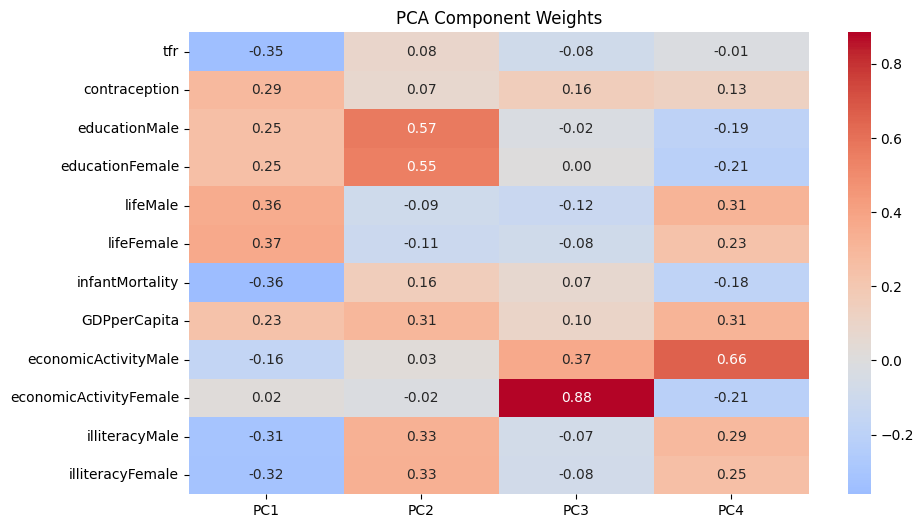

In [ ]:

loadings = pd.DataFrame(
    pca.components_.T,
    columns=[
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    index=X_clean.columns
)

display(loadings.round(3))

plt.figure(figsize=(10, 6))

sns.heatmap(
    loadings.iloc[:, :min(4, loadings.shape[1])],
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("PCA Component Weights")
plt.show()


Countries with higher PC1 scores would tend to have higher income and life expectancy, but lower fertility.
The signs depend on how PCA orients each component, so the important thing is to interpret the variables together.

In [ ]:

X_cluster = X_pca[:, :n_components_90]

print("Original number of variables:", X_clean.shape[1])
print("Number of retained PCs:", X_cluster.shape[1])


Original number of variables: 12
Number of retained PCs: 6


Instead of clustering countries using all original variables, we use the retained principal components.
This can reduce redundancy and remove low-variance dimensions.

,Country,PC1,PC2,Cluster_2
0,Afghanistan,-5.082175,2.642946,1
1,Albania,0.722870,-0.525833,0
2,Algeria,-0.680912,-0.037419,0
3,American.Samoa,1.712769,-1.111205,0
4,Andorra,0.550405,-0.446880,0
5,Angola,-2.740343,0.526613,1
6,Antigua,0.896310,-0.296113,0
7,Argentina,1.513154,-0.738986,0
8,Armenia,1.319197,-1.246432,0
9,Australia,3.836288,2.653954,0


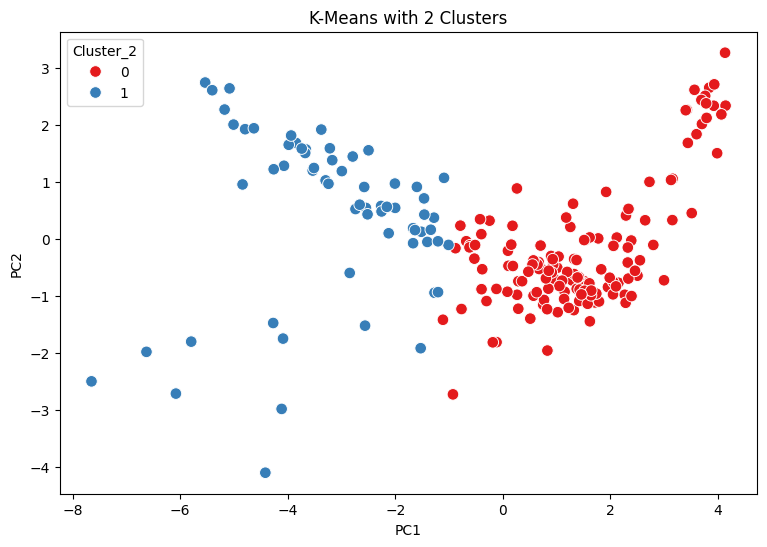

In [ ]:

kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

clusters_2 = kmeans_2.fit_predict(X_cluster)

results = pd.DataFrame({
    "Country": countries,
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster_2": clusters_2
})

display(results.head(20))

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=results,
    x="PC1",
    y="PC2",
    hue="Cluster_2",
    palette="Set1",
    s=70
)

plt.title("K-Means with 2 Clusters")
plt.show()


Here, we force the algorithm to divide countries into exactly two groups.
This represents the traditional developed/developing division.
However, K-Means does not know what developed or developing means. It simply groups countries based on their numerical similarities.
We need to interpret those groups afterward.


In [ ]:

k_values = range(2, min(11, len(X_cluster)))

inertias = []
silhouettes = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_cluster)

    inertias.append(model.inertia_)

    silhouettes.append(
        silhouette_score(X_cluster, labels)
    )

metrics = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette": silhouettes
})

display(metrics.round(3))


,K,Inertia,Silhouette
0,2,1363.679,0.398
1,3,1088.842,0.336
2,4,932.747,0.343
3,5,800.345,0.285
4,6,713.212,0.282
5,7,635.091,0.250
6,8,595.267,0.252
7,9,560.486,0.257
8,10,529.122,0.245


We test different numbers of clusters.
- k = 2: Two groups
- k = 3: Three groups
- k = 4: Four groups
- And so on.
For each k, we calculate two evaluation metrics:
Inertia: Measures how close countries are to their assigned cluster centroid. Lower is better for a fixed k, but inertia always decreases as k increases.
Silhouette score: Measures how well separated the clusters are. Scores range from -1 to 1, with higher values generally indicating clearer separation.

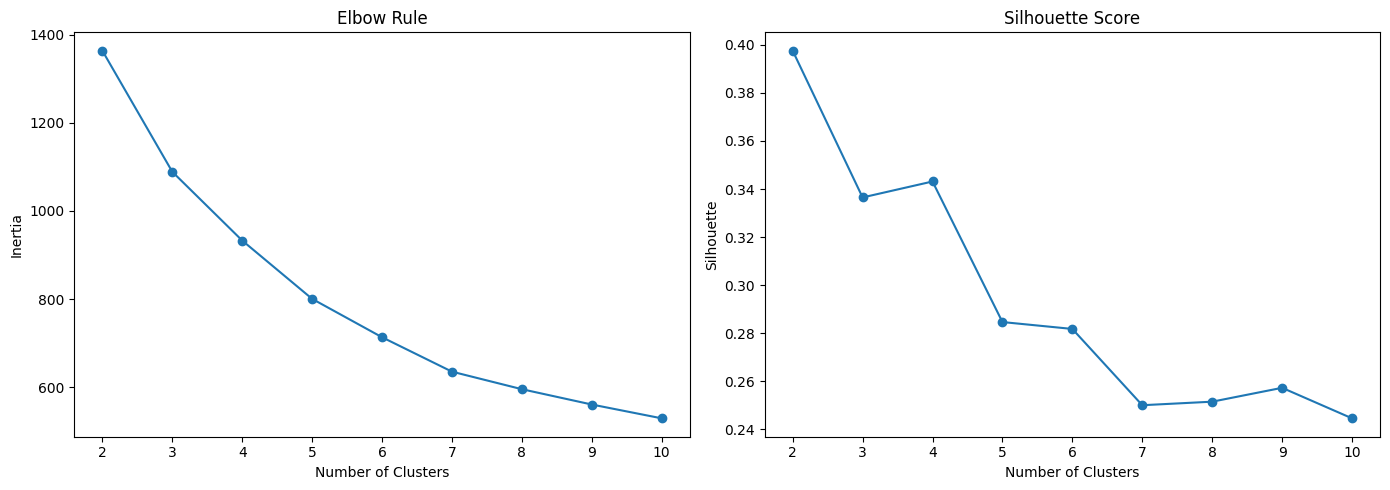

Best k by silhouette score: 2


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    list(k_values),
    inertias,
    marker="o"
)
axes[0].set_title("Elbow Rule")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    list(k_values),
    silhouettes,
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

best_k = metrics.loc[
    metrics["Silhouette"].idxmax(), "K"
]

print("Best k by silhouette score:", best_k)


The Elbow Rule looks for a point where the inertia curve begins to flatten. The silhouette score evaluates how well separated the clusters are; a larger score is better. These metrics may not agree. For this assignment, we compare k=2 against a four-cluster solution, and discuss the trade-off rather than claiming that k=4 wins every metric.

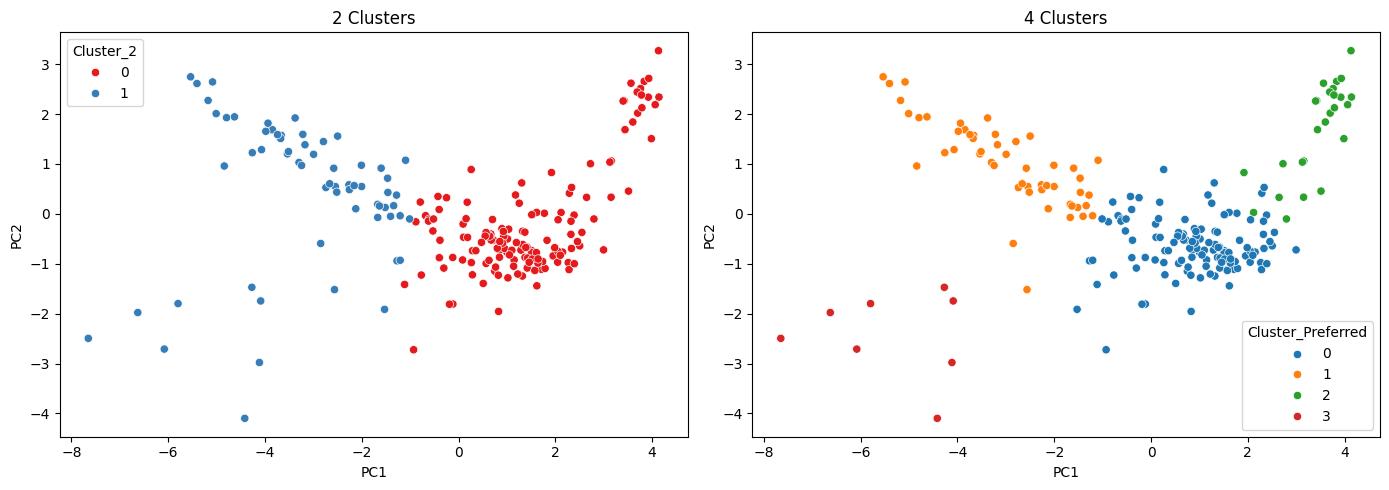

In [ ]:

preferred_k = 4  # Final solution requested: four clusters

# You can change preferred_k after reviewing the graphs.

kmeans_best = KMeans(
    n_clusters=preferred_k,
    random_state=42,
    n_init=20
)

clusters_best = kmeans_best.fit_predict(X_cluster)

results["Cluster_Preferred"] = clusters_best

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=results,
    x="PC1",
    y="PC2",
    hue="Cluster_2",
    palette="Set1",
    ax=axes[0]
)

axes[0].set_title("2 Clusters")

sns.scatterplot(
    data=results,
    x="PC1",
    y="PC2",
    hue="Cluster_Preferred",
    palette="tab10",
    ax=axes[1]
)

axes[1].set_title(f"{preferred_k} Clusters")

plt.tight_layout()
plt.show()


We compare the two-cluster model with the requested four-cluster solution. The PCA scatterplot displays only PC1 and PC2; clustering itself uses the retained principal components. Thus, some separation in the clustering may not be visible in this two-dimensional plot.

In [ ]:

sil_2 = silhouette_score(X_cluster, clusters_2)
sil_best = silhouette_score(X_cluster, clusters_best)

inertia_2 = kmeans_2.inertia_
inertia_best = kmeans_best.inertia_

reduction = (
    (inertia_2 - inertia_best) / inertia_2
) * 100

print("2-cluster silhouette:", round(sil_2, 3))
print("Preferred silhouette:", round(sil_best, 3))
print("Inertia reduction (%):", round(reduction, 2))

print("\nHow the groups change:")
display(pd.crosstab(
    results["Cluster_2"],
    results["Cluster_Preferred"]
))


2-cluster silhouette: 0.398
Preferred silhouette: 0.343
Inertia reduction (%): 31.6

How the groups change:


Cluster_Preferred,0,1,2,3
Cluster_2,,,,
0,117,0,26,0
1,4,52,0,8


This shows how much the clustering changes when we use more groups.
The cross-tabulation is especially useful because it shows how countries from the original two clusters are redistributed.
The inertia reduction measures tighter grouping, not the percentage of the dataset's variance explained by the clusters.

In [ ]:

from sklearn.metrics import pairwise_distances_argmin_min

closest_indices, distances = pairwise_distances_argmin_min(
    kmeans_best.cluster_centers_,
    X_cluster
)

representatives = results.iloc[closest_indices][
    ["Country", "Cluster_Preferred"]
].copy()

representatives["Distance_to_Centroid"] = distances

display(representatives)


,Country,Cluster_Preferred,Distance_to_Centroid
1,Albania,0,0.315625
38,Comoros,1,0.611512
10,Austria,2,0.844592
101,Laos,3,1.960075


For each of the four clusters, we choose the country closest to its centroid in the retained PCA space. This is a reproducible numerical representative, not necessarily the most famous or the only typical country. We then inspect the original-variable cluster profiles to interpret each group.

,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
Cluster,,,,,,,,,,,,
0,-0.34,0.23,-0.11,-0.05,0.42,0.45,-0.45,-0.17,-0.09,-0.07,-0.47,-0.52
1,1.10,-0.89,-0.10,-0.06,-1.25,-1.30,1.28,-0.56,0.35,-0.18,1.14,1.20
2,-1.08,1.16,1.66,1.43,1.08,1.07,-0.94,2.08,-0.44,0.40,-0.46,-0.40
3,1.44,-1.41,-3.03,-3.51,-1.76,-1.75,1.55,-0.64,0.59,0.98,1.20,1.32


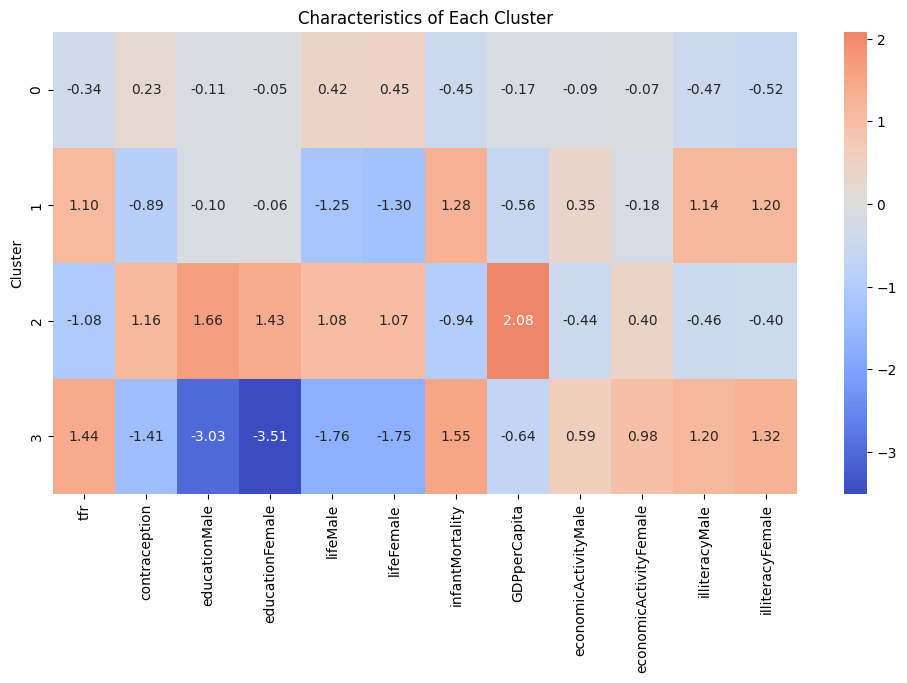


CLUSTER 0
Countries: Albania, Algeria, American.Samoa, Andorra, Antigua, Argentina, Armenia, Azerbaijan, Bahamas, Bahrain, Barbados, Belarus, Belize, Bolivia, Bosnia, Brazil, Brunei, Bulgaria, Cape.Verde, Chile, China, Colombia, Cook.Islands, Costa.Rica, Croatia, Cuba, Cyprus, Czech.Republic, Dominica, Dominican.Republic, Ecuador, El.Salvador, Estonia, Fiji, French.Guiana, French.Polynesia, Gaza.Strip, Georgia, Grenada, Guadeloupe, Guam, Guyana, Honduras, Hungary, Indonesia, Iran, Israel, Italy, Jamaica, Jordan, Kazakhstan, Kiribati, Korea.Dem.Peoples.Rep, Kuwait, Kyrgyzstan, Latvia, Lebanon, Libya, Lithuania, Macau, Macedonia, Malaysia, Maldives, Malta, Marshall.Islands, Martinique, Mauritius, Mexico, Micronesia, Moldova, Monaco, Mongolia, Myanmar, Netherlands.Antilles, New.Caledonia, Nicaragua, Northern.Mariana.Islands, Oman, Palau, Panama, Paraguay, Peru, Philippines, Poland, Puerto.Rico, Qatar, Reunion, Romania, Russia, Saint.Kitts, Saint.Lucia, Samoa, San.Marino, Sao.Tome, Saudi.

lifeFemale       0.445972
lifeMale         0.420940
contraception    0.226736
Name: 0, dtype: float64

Lowest relative indicators:


illiteracyFemale   -0.518243
illiteracyMale     -0.472617
infantMortality    -0.449695
Name: 0, dtype: float64


CLUSTER 1
Countries: Afghanistan, Angola, Bangladesh, Benin, Bhutan, Botswana, Cambodia, Cameroon, Central.African.Rep, Chad, Comoros, Congo, Djibouti, East.Timor, Egypt, Equatorial.Guinea, Ethiopia, Gabon, Ghana, Guatemala, Guinea, Guinea.Bissau, Haiti, India, Iraq, Ivory.Coast, Kenya, Lesotho, Liberia, Madagascar, Malawi, Mali, Mauritania, Morocco, Namibia, Nepal, Niger, Nigeria, Pakistan, Papua.New.Guinea, Rwanda, Senegal, Sierra.Leone, Somalia, Sudan, Swaziland, Tanzania, Togo, Uganda, Vanuatu, Yemen, Zimbabwe
Total: 52
Highest relative indicators:


...

tfr               -1.078191
infantMortality   -0.943606
illiteracyMale    -0.458035
Name: 2, dtype: float64


CLUSTER 3
Countries: Burkina.Faso, Burundi, Dem.Rep.of.the.Congo, Eritrea, Gambia, Laos, Mozambique, Zambia
Total: 8
Highest relative indicators:


infantMortality     1.553582
tfr                 1.442425
illiteracyFemale    1.316350
Name: 3, dtype: float64

Lowest relative indicators:


educationFemale   -3.506565
educationMale     -3.025413
lifeMale          -1.760958
Name: 3, dtype: float64

In [ ]:

profiles = pd.DataFrame(
    X_scaled,
    columns=X_clean.columns
)

profiles["Cluster"] = clusters_best

cluster_means = profiles.groupby("Cluster").mean()

display(cluster_means.round(2))

plt.figure(figsize=(12, 6))

sns.heatmap(
    cluster_means,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Characteristics of Each Cluster")
plt.show()

for cluster in range(preferred_k):
    print(f"\nCLUSTER {cluster}")

    members = results.loc[
        results["Cluster_Preferred"] == cluster,
        "Country"
    ]

    print("Countries:", ", ".join(members.tolist()))
    print("Total:", len(members))

    print("Highest relative indicators:")
    display(
        cluster_means.loc[cluster]
        .sort_values(ascending=False)
        .head(3)
    )

    print("Lowest relative indicators:")
    display(
        cluster_means.loc[cluster]
        .sort_values()
        .head(3)
    )


The heatmap shows the average standardized values for each cluster.
- Positive values: Above the overall dataset average.
- Negative values: Below the overall dataset average.
- Values near zero: Close to the overall average.
For example, a cluster with relatively high life expectancy and income and low fertility might represent countries with higher socioeconomic development.
The actual cluster descriptions must come from your output.

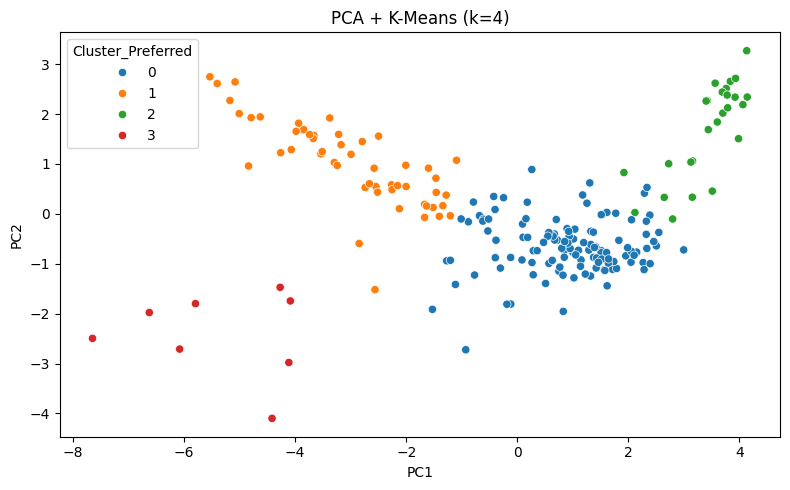

Files saved successfully.


In [ ]:

df.to_csv("UN_imputed.csv", index=False)
results.to_csv("UN_cluster_results.csv", index=False)
metrics.to_csv("clustering_metrics.csv", index=False)
cluster_means.to_csv("cluster_profiles.csv")
representatives.to_csv(
    "representative_countries.csv",
    index=False
)

# Save key figures
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=results,
    x="PC1",
    y="PC2",
    hue="Cluster_Preferred",
    palette="tab10"
)
plt.title(f"PCA + K-Means (k={preferred_k})")
plt.tight_layout()
plt.savefig("PCA_Clusters.png", dpi=200)
plt.show()

print("Files saved successfully.")


This saves the original dataset, country cluster assignments, clustering evaluation metrics, cluster profiles, and a visualization.
You can download these files from the Colab file sidebar and upload them to your GitHub repository, together with the notebook and your completed README.

# README — PCA and clustering of UN country data

## Research question
Can the world be meaningfully divided into only two groups, or does the data suggest a more complex structure?

## Data preparation
The dataset contains 207 countries/territories and 12 numerical indicators plus country and region labels. Country names and region labels are not used as PCA inputs. Missing numerical values are imputed with each variable's median. IQR flags are used to identify potential outliers; the flagged values are retained because extreme differences between countries are substantively relevant, while standardization limits scale dominance. Numerical variables are standardized to mean 0 and standard deviation 1 so that GDP, life expectancy, fertility, and percentage indicators are comparable.

## PCA
PCA is fitted to the 12 standardized numerical variables. PC1 explains about 53.19%, PC2 13.10%, PC3 9.35%, PC4 8.41%, and PC5 5.59% of variance. The first five components explain 89.64%; six components are required to exceed 90% (about 93.63%). PC1 mainly contrasts higher life expectancy and lower fertility, infant mortality, and illiteracy; PC2 is strongly associated with male and female education. Later components capture additional patterns, including women's economic activity. PCA is useful for reducing correlated variables, but retaining six PCs is needed to preserve over 90% of the variance.

## Clustering results and interpretation
The notebook compares k=2 through k=10 using inertia (Elbow Rule) and silhouette score, then contrasts k=2 with the requested four-cluster solution. The silhouette score is highest at k=2 (approximately 0.398), while k=4 is lower (approximately 0.343 in the current run). Inertia decreases as k increases; the four-cluster solution reduces inertia relative to k=2 and offers more detailed groups. The metrics do not prove that four clusters are objectively optimal, so k=4 is used as the requested interpretive solution and its trade-off is stated explicitly.

## Answers to the six research questions
1. **Are two clusters meaningful?** They provide a useful broad contrast, but they simplify a continuum of countries into only two groups and can hide important differences within each group.
2. **How many clusters do the metrics suggest?** The silhouette score favours k=2. The elbow curve should be interpreted visually; k=4 is a defensible richer solution for this assignment if the four profiles are interpretable, but it is not the silhouette winner.
3. **How does k=2 compare with k=4?** Four clusters reduce inertia because each cluster can be more internally compact. Compare the printed metrics and cross-tabulation in the notebook; the lower silhouette at k=4 means the groups are not as cleanly separated by that metric.
4. **Does this support Factfulness?** The results support caution about a simple developed/developing binary: the four-cluster solution can expose multiple socioeconomic profiles. However, this is evidence of useful complexity, not proof that exactly four natural groups exist.
5. **What does PCA reveal?** Health/longevity, fertility, infant mortality, illiteracy, education, and economic participation are important dimensions differentiating countries. PC1 is the broadest development-related contrast; PC2 is strongly education-related.
6. **How should clusters be described?** Use the four representative countries printed in `representative_countries.csv` and the cluster profile heatmap/table. Describe each using the cluster means in original standardized-variable terms: positive values are above the dataset mean and negative values below. Avoid treating cluster numbers as a ranking; K-Means labels are arbitrary. Use actual values printed by the notebook to complete the four country-specific descriptions.

